In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/MLPROJECT/DataCo_sampled_reduced.csv")
print(df.shape)

(45000, 31)


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Type                           45000 non-null  object 
 1   Days for shipment (scheduled)  45000 non-null  int64  
 2   Benefit per order              45000 non-null  float64
 3   Sales per customer             45000 non-null  float64
 4   Late_delivery_risk             45000 non-null  int64  
 5   Category Id                    45000 non-null  int64  
 6   Category Name                  45000 non-null  object 
 7   Customer City                  45000 non-null  object 
 8   Customer Country               45000 non-null  object 
 9   Customer Segment               45000 non-null  object 
 10  Customer State                 45000 non-null  object 
 11  Department Id                  45000 non-null  int64  
 12  Department Name                45000 non-null 

In [4]:
df.isnull().sum().sort_values(ascending=False)

,0
Type,0
Days for shipment (scheduled),0
Benefit per order,0
Sales per customer,0
Late_delivery_risk,0
Category Id,0
Category Name,0
Customer City,0
Customer Country,0
Customer Segment,0


In [5]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [6]:
df.describe()

,Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Department Id,Latitude,Longitude,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Sales
count,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000
mean,2.935089,21.584356,182.970124,0.548289,31.798622,5.439044,29.780181,-84.863084,20.604500,0.101835,141.578785,0.118214,203.574376
std,1.372211,107.683575,120.873720,0.497668,15.669735,1.634064,9.810272,21.493633,21.692863,0.070388,140.610114,0.471470,132.942497
min,0.000000,-4274.979980,7.490000,0.000000,2.000000,2.000000,-33.937553,-158.025986,0.000000,0.000000,9.990000,-2.750000,9.990000
25%,2.000000,6.720000,104.379997,0.000000,18.000000,4.000000,18.265718,-98.469292,5.500000,0.040000,50.000000,0.070000,119.980003
50%,4.000000,31.500000,163.990005,1.000000,29.000000,5.000000,33.212955,-76.777069,14.000000,0.100000,65.000000,0.270000,199.919998
75%,4.000000,64.739998,246.149994,1.000000,45.000000,7.000000,39.297794,-66.370583,29.990000,0.160000,199.990005,0.360000,299.950012
max,4.000000,864.000000,1899.989990,1.000000,76.000000,12.000000,48.770958,115.263077,400.000000,0.250000,1999.989990,0.500000,1999.989990


In [7]:
df['Late_delivery_risk'].value_counts()
print(df['Late_delivery_risk'].value_counts(normalize=True) * 100)

Late_delivery_risk
1    54.828889
0    45.171111
Name: proportion, dtype: float64


In [8]:
df['Benefit per order'].sort_values().head(10)

,Benefit per order
13805,-4274.979980
12915,-3366.000000
10962,-2592.000000
18716,-2328.000000
32498,-2255.250000
6839,-2184.000000
19866,-2184.000000
6268,-1336.369995
18060,-1160.130005
26281,-1088.949951


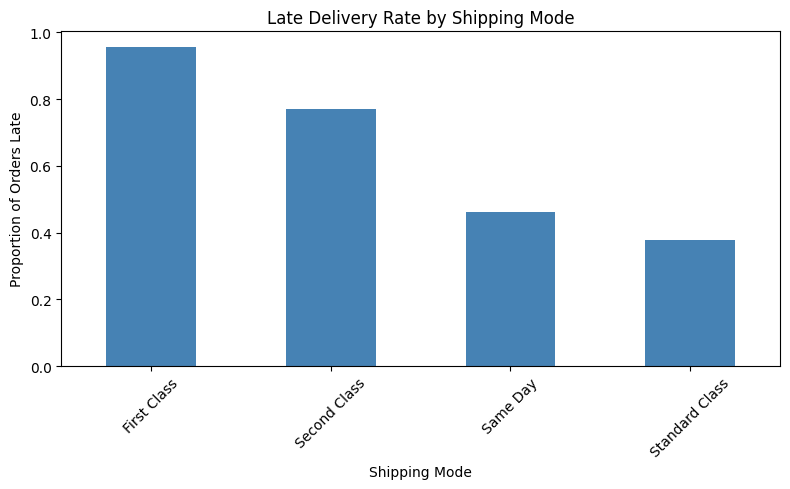

In [9]:
import matplotlib.pyplot as plt

late_by_shipping = df.groupby('Shipping Mode')['Late_delivery_risk'].mean().sort_values(ascending=False)

plt.figure(figsize=(8,5))
late_by_shipping.plot(kind='bar', color='steelblue')
plt.title('Late Delivery Rate by Shipping Mode')
plt.ylabel('Proportion of Orders Late')
plt.xlabel('Shipping Mode')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

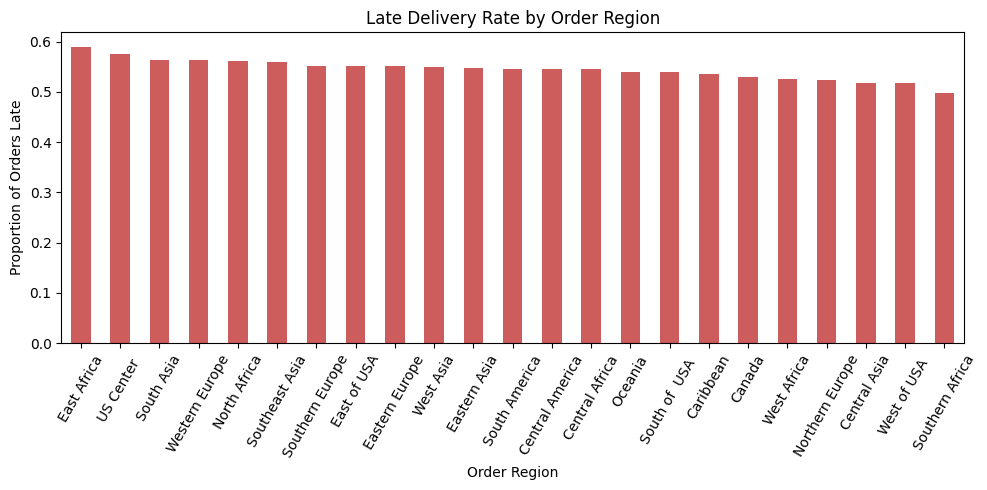

In [10]:
late_by_region = df.groupby('Order Region')['Late_delivery_risk'].mean().sort_values(ascending=False)

plt.figure(figsize=(10,5))
late_by_region.plot(kind='bar', color='indianred')
plt.title('Late Delivery Rate by Order Region')
plt.ylabel('Proportion of Orders Late')
plt.xlabel('Order Region')
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

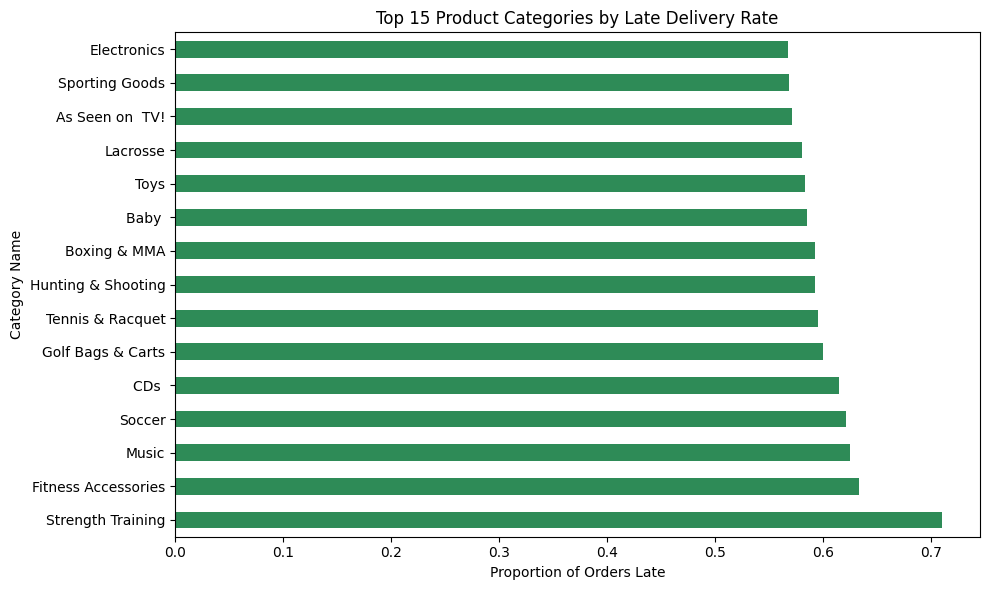

In [11]:
late_by_category = df.groupby('Category Name')['Late_delivery_risk'].mean().sort_values(ascending=False).head(15)

plt.figure(figsize=(10,6))
late_by_category.plot(kind='barh', color='seagreen')
plt.title('Top 15 Product Categories by Late Delivery Rate')
plt.xlabel('Proportion of Orders Late')
plt.ylabel('Category Name')
plt.tight_layout()
plt.show()

In [12]:
categorical_cols = df.select_dtypes(include='object').columns.tolist()
numeric_cols = df.select_dtypes(exclude='object').columns.tolist()

print("Categorical columns:", categorical_cols)
print("\nNumeric columns:", numeric_cols)

Categorical columns: ['Type', 'Category Name', 'Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Market', 'Order City', 'Order Country', 'order date (DateOrders)', 'Order Region', 'Order State', 'Order Status', 'Product Image', 'Product Name', 'shipping date (DateOrders)', 'Shipping Mode']

Numeric columns: ['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Late_delivery_risk', 'Category Id', 'Department Id', 'Latitude', 'Longitude', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Sales']


In [13]:
df['order date (DateOrders)'] = pd.to_datetime(df['order date (DateOrders)'])

df['order_month'] = df['order date (DateOrders)'].dt.month
df['order_weekday'] = df['order date (DateOrders)'].dt.dayofweek  # 0=Monday, 6=Sunday
df['order_hour'] = df['order date (DateOrders)'].dt.hour

print(df[['order date (DateOrders)', 'order_month', 'order_weekday', 'order_hour']].head())

  order date (DateOrders)  order_month  order_weekday  order_hour
0     2017-09-21 09:49:00            9              3           9
1     2015-12-10 15:27:00           12              3          15
2     2015-07-05 08:19:00            7              6           8
3     2016-10-22 11:41:00           10              5          11
4     2016-07-30 16:42:00            7              5          16


In [14]:
drop_for_model = [
    'order date (DateOrders)',
    'shipping date (DateOrders)',
    'Product Image',
    'Product Name',
]

df_model = df.drop(columns=[c for c in drop_for_model if c in df.columns])
print(df_model.shape)
print(df_model.columns.tolist())

(45000, 30)
['Type', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Sales', 'Order Region', 'Order State', 'Order Status', 'Shipping Mode', 'order_month', 'order_weekday', 'order_hour']


In [15]:
# Check how many unique values each categorical column has
remaining_categorical = df_model.select_dtypes(include='object').columns.tolist()

for col in remaining_categorical:
    print(col, "->", df_model[col].nunique(), "unique values")

Type -> 4 unique values
Category Name -> 50 unique values
Customer City -> 563 unique values
Customer Country -> 2 unique values
Customer Segment -> 3 unique values
Customer State -> 45 unique values
Department Name -> 11 unique values
Market -> 5 unique values
Order City -> 3297 unique values
Order Country -> 156 unique values
Order Region -> 23 unique values
Order State -> 1029 unique values
Order Status -> 9 unique values
Shipping Mode -> 4 unique values


In [16]:
drop_high_cardinality = [
    'Customer City', 'Order City', 'Order State', 'Customer State',
    'Order Country', 'Category Name'
]

df_model = df_model.drop(columns=[c for c in drop_high_cardinality if c in df_model.columns])
print(df_model.shape)

(45000, 24)


In [17]:
df_encoded = pd.get_dummies(df_model, columns=[
    'Type', 'Customer Country', 'Customer Segment', 'Department Name',
    'Market', 'Order Region', 'Order Status', 'Shipping Mode'
], drop_first=True)

print(df_encoded.shape)
print(df_encoded.columns.tolist())

(45000, 69)
['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Late_delivery_risk', 'Category Id', 'Department Id', 'Latitude', 'Longitude', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Sales', 'order_month', 'order_weekday', 'order_hour', 'Type_DEBIT', 'Type_PAYMENT', 'Type_TRANSFER', 'Customer Country_Puerto Rico', 'Customer Segment_Corporate', 'Customer Segment_Home Office', 'Department Name_Book Shop', 'Department Name_Discs Shop', 'Department Name_Fan Shop', 'Department Name_Fitness', 'Department Name_Footwear', 'Department Name_Golf', 'Department Name_Health and Beauty ', 'Department Name_Outdoors', 'Department Name_Pet Shop', 'Department Name_Technology', 'Market_Europe', 'Market_LATAM', 'Market_Pacific Asia', 'Market_USCA', 'Order Region_Caribbean', 'Order Region_Central Africa', 'Order Region_Central America', 'Order Region_Central Asia', 'Order Region_East Africa', 'Order Region_East of U

In [18]:
X = df_encoded.drop(columns=['Late_delivery_risk'])
y = df_encoded['Late_delivery_risk']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (45000, 68)
y shape: (45000,)


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (36000, 68)
Test shape: (9000, 68)


In [20]:
from sklearn.preprocessing import StandardScaler

numeric_features = ['Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer',
                     'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price',
                     'Order Item Profit Ratio', 'Sales', 'Latitude', 'Longitude']

scaler = StandardScaler()
X_train[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test[numeric_features] = scaler.transform(X_test[numeric_features])

print("Scaling done")
print(X_train[numeric_features].describe())

Scaling done
       Days for shipment (scheduled)  Benefit per order  Sales per customer  \
count                   3.600000e+04       3.600000e+04        3.600000e+04   
mean                   -8.842310e-17       2.881646e-17       -1.435888e-16   
std                     1.000014e+00       1.000014e+00        1.000014e+00   
min                    -2.130703e+00      -4.008783e+01       -1.440439e+00   
25%                    -6.768358e-01      -1.385431e-01       -6.488208e-01   
50%                     7.770315e-01       9.128415e-02       -1.582465e-01   
75%                     7.770315e-01       4.033808e-01        5.281953e-01   
max                     7.770315e-01       7.860112e+00        1.412857e+01   

       Order Item Discount  Order Item Discount Rate  \
count         3.600000e+04              3.600000e+04   
mean          9.424560e-17              2.388213e-16   
std           1.000014e+00              1.000014e+00   
min          -9.472119e-01             -1.445034e+0

In [21]:
import joblib

joblib.dump(scaler, '/content/drive/MyDrive/MLPROJECT/scaler.pkl')
joblib.dump(list(X_train.columns), '/content/drive/MyDrive/MLPROJECT/feature_columns.pkl')
joblib.dump(numeric_features, '/content/drive/MyDrive/MLPROJECT/numeric_features.pkl')

print("Saved scaler and column info")

Saved scaler and column info


In [22]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedKFold
import pandas as pd

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

models = {
    'Baseline (Dummy)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=1000)
}

results = {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    results[name] = {m: scores[f'test_{m}'].mean() for m in scoring}

print(pd.DataFrame(results).T.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

                     accuracy  precision  recall      f1  roc_auc
Baseline (Dummy)       0.5483     0.5483  1.0000  0.7082   0.5000
Logistic Regression    0.7260     0.8852  0.5748  0.6970   0.7718


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [24]:
import warnings
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedKFold
import pandas as pd

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

models = {
    'Baseline (Dummy)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=3000))
    ])
}

results = {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    results[name] = {m: scores[f'test_{m}'].mean() for m in scoring}

print(pd.DataFrame(results).T.round(4))

                     accuracy  precision  recall      f1  roc_auc
Baseline (Dummy)       0.5483     0.5483  1.0000  0.7082    0.500
Logistic Regression    0.7255     0.8862  0.5729  0.6958    0.772


In [25]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models2 = {
    'Decision Tree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1,
                             eval_metric='logloss', random_state=42)
}

for name, model in models2.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    results[name] = {m: scores[f'test_{m}'].mean() for m in scoring}

print(pd.DataFrame(results).T.round(4))

                     accuracy  precision  recall      f1  roc_auc
Baseline (Dummy)       0.5483     0.5483  1.0000  0.7082   0.5000
Logistic Regression    0.7255     0.8862  0.5729  0.6958   0.7720
Decision Tree          0.7350     0.8845  0.5942  0.7108   0.7963
Random Forest          0.7290     0.8764  0.5887  0.7042   0.8017
XGBoost                0.7330     0.8554  0.6174  0.7171   0.8087


In [26]:
status_cols = [c for c in X_train.columns if c.startswith('Order Status_')]
print("Status columns:", status_cols)

xgb = XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1,
                    eval_metric='logloss', random_state=42)

with_status = cross_validate(xgb, X_train, y_train, cv=cv, scoring=scoring)
without_status = cross_validate(xgb, X_train.drop(columns=status_cols), y_train, cv=cv, scoring=scoring)

comparison = pd.DataFrame({
    'With Order Status': {m: with_status[f'test_{m}'].mean() for m in scoring},
    'Without Order Status': {m: without_status[f'test_{m}'].mean() for m in scoring}
}).T.round(4)
print(comparison)

Status columns: ['Order Status_CLOSED', 'Order Status_COMPLETE', 'Order Status_ON_HOLD', 'Order Status_PAYMENT_REVIEW', 'Order Status_PENDING', 'Order Status_PENDING_PAYMENT', 'Order Status_PROCESSING', 'Order Status_SUSPECTED_FRAUD']
                      accuracy  precision  recall      f1  roc_auc
With Order Status        0.733     0.8554  0.6174  0.7171   0.8087
Without Order Status     0.717     0.8250  0.6141  0.7040   0.7807


In [27]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Remove Order Status columns from train and test
status_cols = [c for c in X_train.columns if c.startswith('Order Status_')]
X_train = X_train.drop(columns=status_cols)
X_test = X_test.drop(columns=status_cols)
print("New shapes:", X_train.shape, X_test.shape)

# Save everything the API will need later
base = '/content/drive/MyDrive/MLPROJECT/'
joblib.dump(scaler, base + 'scaler.pkl')
joblib.dump(numeric_features, base + 'numeric_features.pkl')
joblib.dump(list(X_train.columns), base + 'feature_columns.pkl')

all_models = {
    'Baseline (Dummy)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': Pipeline([('scaler', StandardScaler()),
                                     ('clf', LogisticRegression(max_iter=3000))]),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1,
                             eval_metric='logloss', random_state=42)
}

results_v2 = {}
for name, model in all_models.items():
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    results_v2[name] = {m: s[f'test_{m}'].mean() for m in scoring}

print(pd.DataFrame(results_v2).T.round(4))

New shapes: (36000, 60) (9000, 60)
                     accuracy  precision  recall      f1  roc_auc
Baseline (Dummy)       0.5483     0.5483  1.0000  0.7082   0.5000
Logistic Regression    0.7081     0.8487  0.5690  0.6812   0.7463
Decision Tree          0.7159     0.8407  0.5944  0.6964   0.7669
Random Forest          0.7205     0.8570  0.5883  0.6976   0.7808
XGBoost                0.7170     0.8250  0.6141  0.7040   0.7807


In [28]:
from sklearn.model_selection import RandomizedSearchCV

rf_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [8, 12, 16, 20],
    'min_samples_leaf': [1, 3, 5, 10],
    'max_features': ['sqrt', 0.5]
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=-1, random_state=42),
    rf_params, n_iter=12, cv=3, scoring='roc_auc',
    random_state=42, n_jobs=1, verbose=1
)
rf_search.fit(X_train, y_train)

print("Best RF params:", rf_search.best_params_)
print("Best RF CV ROC-AUC:", round(rf_search.best_score_, 4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best RF params: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}
Best RF CV ROC-AUC: 0.787


In [29]:
xgb_params = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [3, 4, 5, 6, 8],
    'learning_rate': [0.03, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.85, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0]
}

xgb_search = RandomizedSearchCV(
    XGBClassifier(eval_metric='logloss', random_state=42),
    xgb_params, n_iter=15, cv=3, scoring='roc_auc',
    random_state=42, n_jobs=1, verbose=1
)
xgb_search.fit(X_train, y_train)

print("Best XGB params:", xgb_search.best_params_)
print("Best XGB CV ROC-AUC:", round(xgb_search.best_score_, 4))

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best XGB params: {'subsample': 0.85, 'n_estimators': 200, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
Best XGB CV ROC-AUC: 0.7821


In [30]:
import os

joblib.dump(rf_search.best_estimator_, base + 'rf_tuned.pkl', compress=3)
joblib.dump(xgb_search.best_estimator_, base + 'xgb_tuned.pkl')

for f in ['rf_tuned.pkl', 'xgb_tuned.pkl']:
    print(f, round(os.path.getsize(base + f) / 1e6, 1), 'MB')

rf_tuned.pkl 23.8 MB
xgb_tuned.pkl 2.0 MB


In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

final_models = {
    'Baseline (Dummy)': all_models['Baseline (Dummy)'],
    'Logistic Regression': all_models['Logistic Regression'],
    'Decision Tree': all_models['Decision Tree'],
    'Random Forest (tuned)': rf_search.best_estimator_,
    'XGBoost (tuned)': xgb_search.best_estimator_
}

test_results = {}
for name, model in final_models.items():
    if name in ['Baseline (Dummy)', 'Logistic Regression', 'Decision Tree']:
        model.fit(X_train, y_train)   # tuned models are already fitted on the training data
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    test_results[name] = {
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred),
        'f1': f1_score(y_test, pred),
        'roc_auc': roc_auc_score(y_test, proba)
    }

print(pd.DataFrame(test_results).T.round(4))

                       accuracy  precision  recall      f1  roc_auc
Baseline (Dummy)         0.5483     0.5483  1.0000  0.7083   0.5000
Logistic Regression      0.7117     0.8539  0.5720  0.6851   0.7518
Decision Tree            0.7203     0.8504  0.5945  0.6998   0.7685
Random Forest (tuned)    0.7243     0.8524  0.6014  0.7052   0.7898
XGBoost (tuned)          0.7229     0.8482  0.6024  0.7045   0.7894


2:1 -> best threshold 0.32 | cost 14878 | at 0.5: 18073 | flag-everything: 16262
3:1 -> best threshold 0.20 | cost 15251 | at 0.5: 26001 | flag-everything: 16262
5:1 -> best threshold 0.13 | cost 15253 | at 0.5: 41857 | flag-everything: 16262


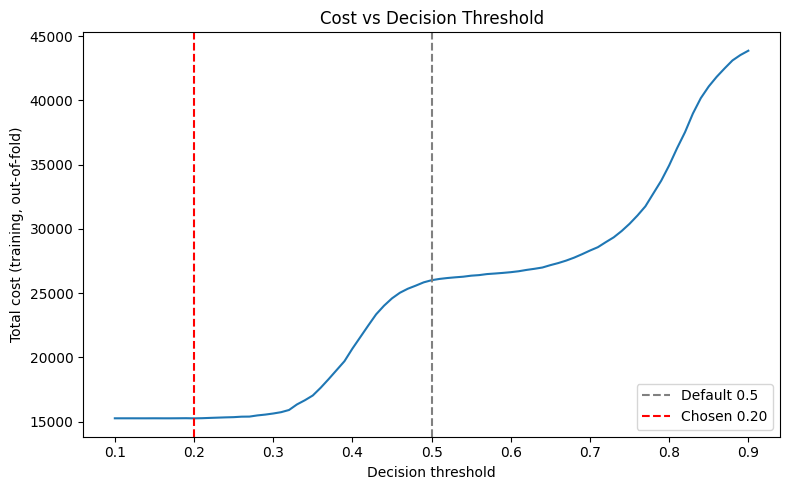

                 accuracy  precision  recall      f1  missed_late  \
Default 0.5        0.7229     0.8482  0.6024  0.7045       1962.0   
Cost-based 0.20    0.5741     0.5629  0.9998  0.7202          1.0   

                 false_alarms  total_cost  
Default 0.5             532.0      6418.0  
Cost-based 0.20        3832.0      3835.0  


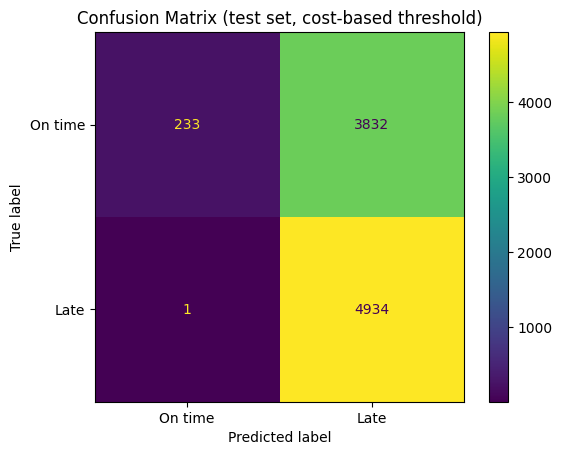

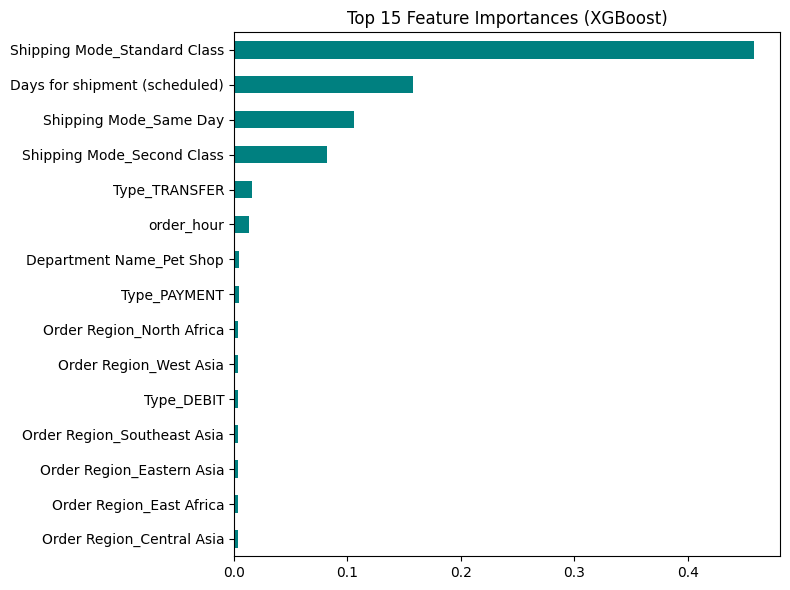

Shipping Mode_Standard Class     0.4581
Days for shipment (scheduled)    0.1575
Shipping Mode_Same Day           0.1058
Shipping Mode_Second Class       0.0818
Type_TRANSFER                    0.0162
order_hour                       0.0130
Department Name_Pet Shop         0.0041
Type_PAYMENT                     0.0040
Order Region_North Africa        0.0039
Order Region_West Asia           0.0039
Type_DEBIT                       0.0038
Order Region_Southeast Asia      0.0036
Order Region_Eastern Asia        0.0035
Order Region_East Africa         0.0034
Order Region_Central Asia        0.0034
dtype: float32
                orders  late_rate  error_rate  missed_late_rate
mode                                                           
First Class       1360      0.955       0.045               0.0
Same Day           443      0.460       0.025               0.0
Second Class      1794      0.782       0.218               0.0
Standard Class    5403      0.376       0.624               0.0



In [32]:
import os, numpy as np, matplotlib.pyplot as plt, joblib
import sklearn, xgboost
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, ConfusionMatrixDisplay)

base = '/content/drive/MyDrive/MLPROJECT/'
os.makedirs(base + 'plots', exist_ok=True)
final_xgb = xgb_search.best_estimator_
MAIN_RATIO = 3

# --- 1. Cost-based threshold, chosen on TRAINING data only (out-of-fold) ---
oof = cross_val_predict(final_xgb, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
y_tr = y_train.values

def cost(t, ratio):
    pred = (oof >= t).astype(int)
    fn = ((pred == 0) & (y_tr == 1)).sum()
    fp = ((pred == 1) & (y_tr == 0)).sum()
    return fn * ratio + fp

ths = np.arange(0.10, 0.91, 0.01)
for r in [2, 3, 5]:
    c = [cost(t, r) for t in ths]
    print(f"{r}:1 -> best threshold {ths[int(np.argmin(c))]:.2f} | cost {min(c)} | "
          f"at 0.5: {cost(0.5, r)} | flag-everything: {cost(0.0, r)}")

costs = [cost(t, MAIN_RATIO) for t in ths]
best_t = float(ths[int(np.argmin(costs))])
plt.figure(figsize=(8, 5))
plt.plot(ths, costs)
plt.axvline(0.5, color='grey', linestyle='--', label='Default 0.5')
plt.axvline(best_t, color='red', linestyle='--', label=f'Chosen {best_t:.2f}')
plt.xlabel('Decision threshold'); plt.ylabel('Total cost (training, out-of-fold)')
plt.title('Cost vs Decision Threshold'); plt.legend(); plt.tight_layout()
plt.savefig(base + 'plots/threshold_cost.png', dpi=150); plt.show()
joblib.dump(best_t, base + 'threshold.pkl')

# --- 2. Final test evaluation: default vs cost-based threshold ---
test_proba = final_xgb.predict_proba(X_test)[:, 1]
yt = y_test.values
rows = {}
for label, t in [('Default 0.5', 0.5), (f'Cost-based {best_t:.2f}', best_t)]:
    p = (test_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, p).ravel()
    rows[label] = {'accuracy': round(accuracy_score(yt, p), 4),
                   'precision': round(precision_score(yt, p), 4),
                   'recall': round(recall_score(yt, p), 4),
                   'f1': round(f1_score(yt, p), 4),
                   'missed_late': fn, 'false_alarms': fp,
                   'total_cost': fn * MAIN_RATIO + fp}
print(pd.DataFrame(rows).T)

pred_t = (test_proba >= best_t).astype(int)
ConfusionMatrixDisplay.from_predictions(yt, pred_t, display_labels=['On time', 'Late'])
plt.title('Confusion Matrix (test set, cost-based threshold)')
plt.savefig(base + 'plots/confusion_matrix.png', dpi=150); plt.show()

# --- 3. Feature importance ---
imp = pd.Series(final_xgb.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
imp.iloc[::-1].plot(kind='barh', figsize=(8, 6), color='teal')
plt.title('Top 15 Feature Importances (XGBoost)'); plt.tight_layout()
plt.savefig(base + 'plots/feature_importance.png', dpi=150); plt.show()
print(imp.round(4))

# --- 4. Error analysis by shipping mode ---
ea = pd.DataFrame({'mode': df.loc[X_test.index, 'Shipping Mode'].values, 'y': yt, 'pred': pred_t})
ea['error'] = ea.y != ea.pred
ea['missed_late'] = (ea.y == 1) & (ea.pred == 0)
print(ea.groupby('mode').agg(orders=('y', 'size'), late_rate=('y', 'mean'),
                             error_rate=('error', 'mean'),
                             missed_late_rate=('missed_late', 'mean')).round(3))

# --- 5. Info needed for the API ---
print("\nVersions ->", "scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| pandas", pd.__version__)
for c in ['Type', 'Customer Country', 'Customer Segment', 'Department Name',
          'Market', 'Order Region', 'Shipping Mode']:
    print(c, '->', sorted(df[c].unique().tolist()))

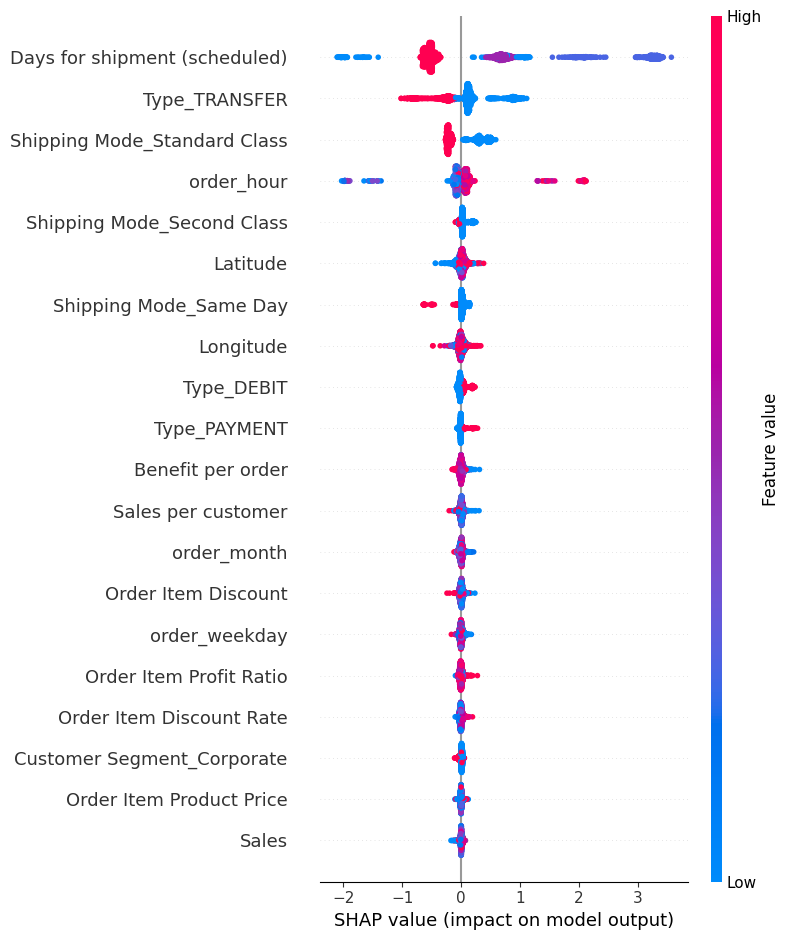

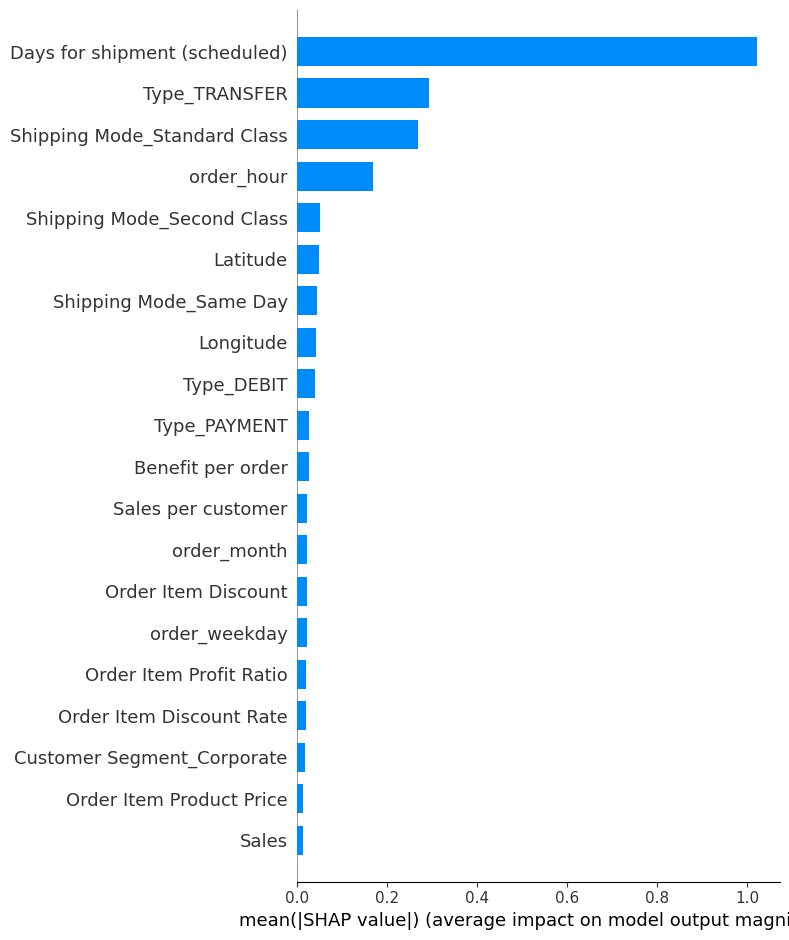

Predicted late probability: 0.417
Days for shipment (scheduled)   -0.617
Shipping Mode_Standard Class    -0.240
Type_TRANSFER                    0.150
Longitude                        0.086
Latitude                         0.077
dtype: float32


In [33]:
!pip install -q shap
import shap, xgboost as xgb

sample = X_test.sample(2000, random_state=42)
contribs = final_xgb.get_booster().predict(xgb.DMatrix(sample), pred_contribs=True)
shap_vals = contribs[:, :-1]          # last column is the bias term

# 1. Beeswarm: which features matter and in which direction
shap.summary_plot(shap_vals, sample, show=False)
plt.tight_layout()
plt.savefig(base + 'plots/shap_summary.png', dpi=150, bbox_inches='tight'); plt.show()

# 2. Bar: average importance
shap.summary_plot(shap_vals, sample, plot_type='bar', show=False)
plt.tight_layout()
plt.savefig(base + 'plots/shap_bar.png', dpi=150, bbox_inches='tight'); plt.show()

# 3. Why was ONE order flagged? (top 5 reasons)
i = 0
reasons = pd.Series(shap_vals[i], index=sample.columns)
print("Predicted late probability:", round(float(final_xgb.predict_proba(sample.iloc[[i]])[0, 1]), 3))
print(reasons.reindex(reasons.abs().sort_values(ascending=False).index).head(5).round(3))

 threshold  recall  precision  flagged_share  false_alarm_rate
      0.20   1.000      0.564          0.971             0.936
      0.25   0.994      0.567          0.961             0.921
      0.30   0.969      0.581          0.914             0.847
      0.35   0.897      0.618          0.796             0.673
      0.40   0.759      0.700          0.595             0.396
      0.45   0.641      0.793          0.443             0.203
      0.50   0.598      0.842          0.390             0.136
      0.55   0.587      0.859          0.375             0.117
      0.60   0.581      0.865          0.368             0.110
      0.65   0.569      0.871          0.358             0.102
      0.70   0.546      0.883          0.339             0.088

Operating threshold: 0.385
                       accuracy  precision  recall     f1  missed_late  false_alarms  cost_3to1  flagged_share
Flag everything           0.548      0.548   1.000  0.708          0.0        4065.0     4065.0          

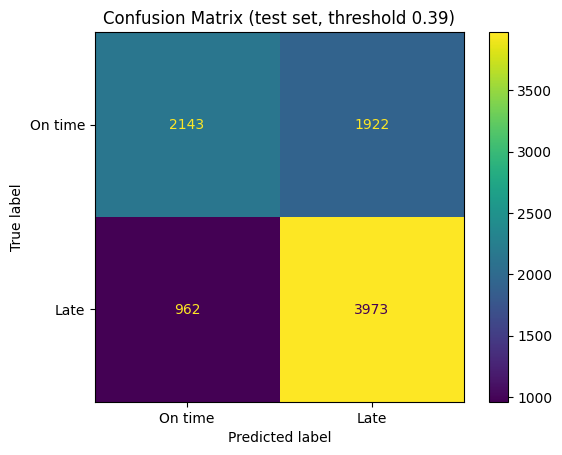

                orders  late_rate  flagged  error_rate  missed_late  \
mode                                                                  
First Class       1360      0.955    1.000       0.045        0.000   
Same Day           443      0.460    0.483       0.023        0.000   
Second Class      1794      0.782    1.000       0.218        0.000   
Standard Class    5403      0.376    0.468       0.448        0.178   

                false_alarm  
mode                         
First Class           0.045  
Same Day              0.023  
Second Class          0.218  
Standard Class        0.270  
First Class - AUC within this mode: 0.898
Same Day - AUC within this mode: 0.997
Second Class - AUC within this mode: 0.624
Standard Class - AUC within this mode: 0.564
            mean  size
order_hour            
0           0.00   114
1           0.00   104
2           0.00    77
3           0.00   120
4           0.00   121
5           0.00    85
6           0.00    95
7           0.00 

In [34]:
import json
from sklearn.metrics import roc_auc_score

# 1. What each threshold does on TRAINING data (out-of-fold)
def stats(proba, y, t):
    pred = (proba >= t).astype(int)
    tp = ((pred==1)&(y==1)).sum(); fn = ((pred==0)&(y==1)).sum()
    fp = ((pred==1)&(y==0)).sum(); tn = ((pred==0)&(y==0)).sum()
    return dict(threshold=round(float(t),3), recall=tp/(tp+fn),
                precision=tp/(tp+fp) if tp+fp else 0,
                flagged_share=pred.mean(), false_alarm_rate=fp/(fp+tn))
print(pd.DataFrame([stats(oof, y_tr, t) for t in np.arange(0.20, 0.71, 0.05)]).round(3).to_string(index=False))

# 2. Operating threshold: highest threshold still catching >= 80% of late orders
TARGET_RECALL = 0.80   # an assumption: state it in your report
grid = np.arange(0.10, 0.90, 0.005)
op_t = float(max(t for t in grid if stats(oof, y_tr, t)['recall'] >= TARGET_RECALL))
print("\nOperating threshold:", round(op_t, 3))

# 3. Compare strategies on the TEST set
comp = {}
for label, t in [('Flag everything', 0.0), ('Default 0.5', 0.5),
                 ('Cost-based 3:1 (0.20)', 0.20), (f'Operating ({op_t:.2f})', op_t)]:
    p = (test_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, p).ravel()
    comp[label] = {'accuracy': accuracy_score(yt, p), 'precision': precision_score(yt, p),
                   'recall': recall_score(yt, p), 'f1': f1_score(yt, p),
                   'missed_late': fn, 'false_alarms': fp, 'cost_3to1': fn*3+fp,
                   'flagged_share': p.mean()}
print(pd.DataFrame(comp).T.round(3).to_string())

# 4. Confusion matrix and save threshold
p_op = (test_proba >= op_t).astype(int)
ConfusionMatrixDisplay.from_predictions(yt, p_op, display_labels=['On time', 'Late'])
plt.title(f'Confusion Matrix (test set, threshold {op_t:.2f})')
plt.savefig(base + 'plots/confusion_matrix_operating.png', dpi=150); plt.show()
joblib.dump(op_t, base + 'threshold.pkl')

# 5. Error analysis by shipping mode, and skill WITHIN each mode
ea = pd.DataFrame({'mode': df.loc[X_test.index, 'Shipping Mode'].values,
                   'y': yt, 'pred': p_op, 'proba': test_proba})
ea['error'] = ea.y != ea.pred
ea['missed_late'] = (ea.y == 1) & (ea.pred == 0)
ea['false_alarm'] = (ea.y == 0) & (ea.pred == 1)
print(ea.groupby('mode').agg(orders=('y','size'), late_rate=('y','mean'), flagged=('pred','mean'),
      error_rate=('error','mean'), missed_late=('missed_late','mean'),
      false_alarm=('false_alarm','mean')).round(3))
for m, g in ea.groupby('mode'):
    print(m, '- AUC within this mode:', round(roc_auc_score(g.y, g.proba), 3))

# 6. Is order_hour meaningful for Same Day orders?
sd = df[df['Shipping Mode'] == 'Same Day']
print(sd.groupby('order_hour')['Late_delivery_risk'].agg(['mean', 'size']).round(2))

# 7. Scheduled days per shipping mode (use these values when testing the API)
print(df.groupby('Shipping Mode')['Days for shipment (scheduled)'].agg(['min', 'max']))

# 8. Files the API needs
cats = {c: sorted(df[c].unique().tolist()) for c in ['Type', 'Customer Country',
        'Customer Segment', 'Department Name', 'Market', 'Order Region', 'Shipping Mode']}
with open(base + 'categories.json', 'w') as f:
    json.dump(cats, f)
print("Saved threshold and categories.json")

In [35]:
mode_tr = df.loc[X_train.index, 'Shipping Mode'].values
rate = y_train.groupby(mode_tr).mean()
mode_score = df.loc[X_test.index, 'Shipping Mode'].map(rate).values
print("Shipping-mode-only AUC (test):", round(roc_auc_score(yt, mode_score), 4))
print("XGBoost AUC (test):", round(roc_auc_score(yt, test_proba), 4))

Shipping-mode-only AUC (test): 0.7338
XGBoost AUC (test): 0.7894
